# Bank Customer Churn Classification

Predicts whether a bank customer will churn (`Exited`) from 10 demographic and account features, comparing four classifiers.

**Note on this revision.** This notebook was corrected from an earlier draft that reported a "perfect" model (0 misclassifications, R² = 1.0). That result was fake, caused by two stacked bugs:
1. The train/test split was built from the full dataframe (still containing the `Exited` label) instead of the feature-only dataframe, so the model was trained with the answer as one of its own inputs. Confirmed by inspecting the broken model's `feature_importances_`: **100% of the importance landed on the `Exited` column itself, 0% on every real feature.**
2. The target is binary (churn / no churn), but the notebook used `DecisionTreeRegressor` instead of `DecisionTreeClassifier`, and evaluated it with `r2_score` — a regression metric with no real meaning for a classification task.

Both are fixed below. There was also no exploratory analysis in the original notebook at all (`matplotlib`/`numpy`/`seaborn` were imported and never used) — Section 2 adds one. See **Limitations** at the end before treating any number here as final.

## 1. Data Loading & Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

In [2]:
# Original notebook hardcoded a path into one machine's Downloads folder
# (C:\Users\User\Downloads\...), which cannot run anywhere else. Use a
# relative path instead -- place the CSV at data/Bank_churn_modelling.csv
# relative to this notebook.

data = pd.read_csv("data/Bank_churn_modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
print("Shape:", data.shape)
print("\nMissing values per column:")
print(data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())

Shape: (10000, 14)

Missing values per column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate rows: 0


In [4]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [5]:
# Drop identifier columns that carry no predictive information
data_new = data.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)
data_new.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Exploratory Data Analysis

Class balance (% of customers):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


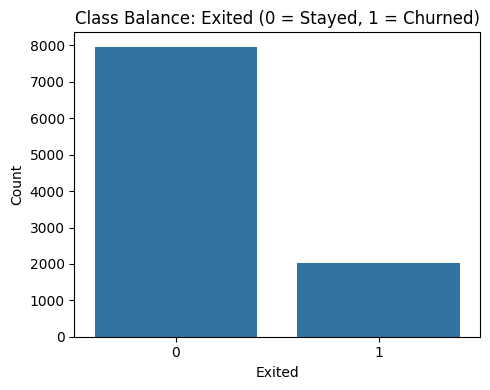

In [6]:
churn_rate = data_new['Exited'].value_counts(normalize=True) * 100
print("Class balance (% of customers):")
print(churn_rate.round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x='Exited', data=data_new)
plt.title('Class Balance: Exited (0 = Stayed, 1 = Churned)')
plt.xlabel('Exited')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

Roughly 80% of customers stayed and 20% churned. This matters for two reasons covered later: accuracy alone is a weak metric here (always predicting "stayed" already scores ~80%), and none of the models below apply class-weighting or resampling to correct for it — see **Limitations**.

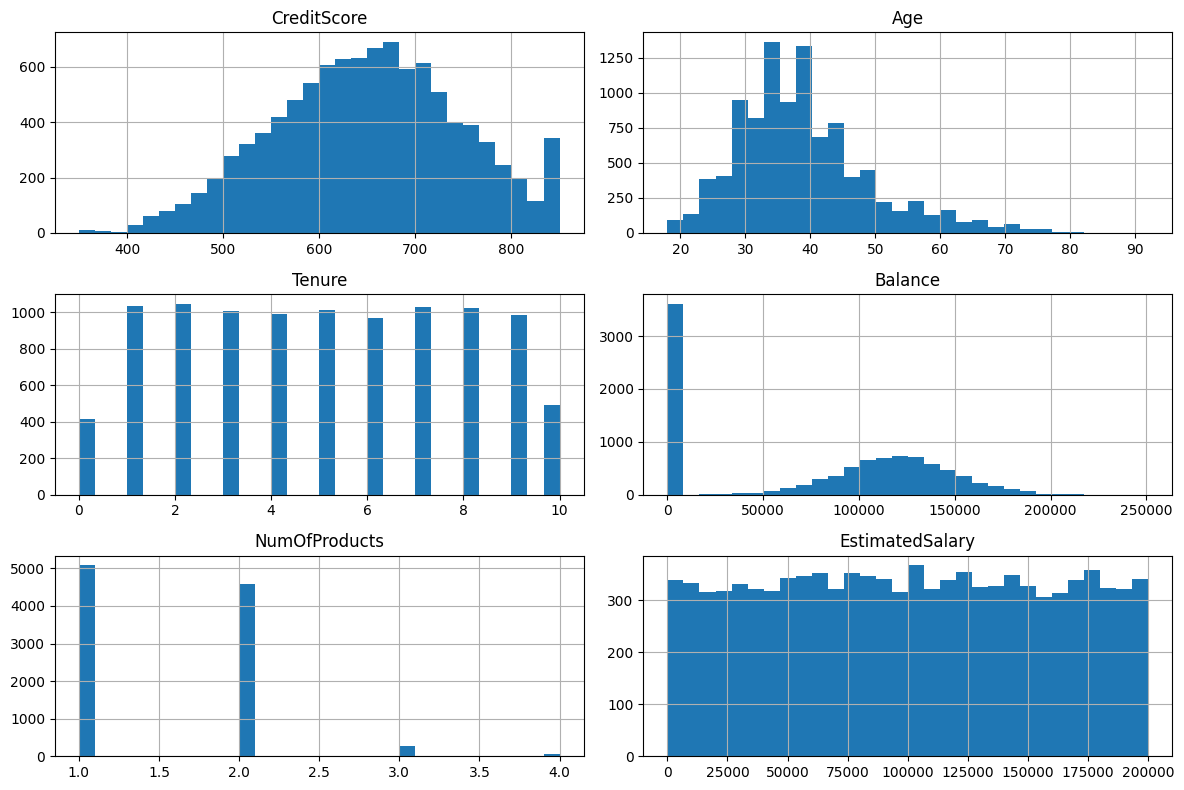

In [7]:
numerical_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

data_new[numerical_features].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

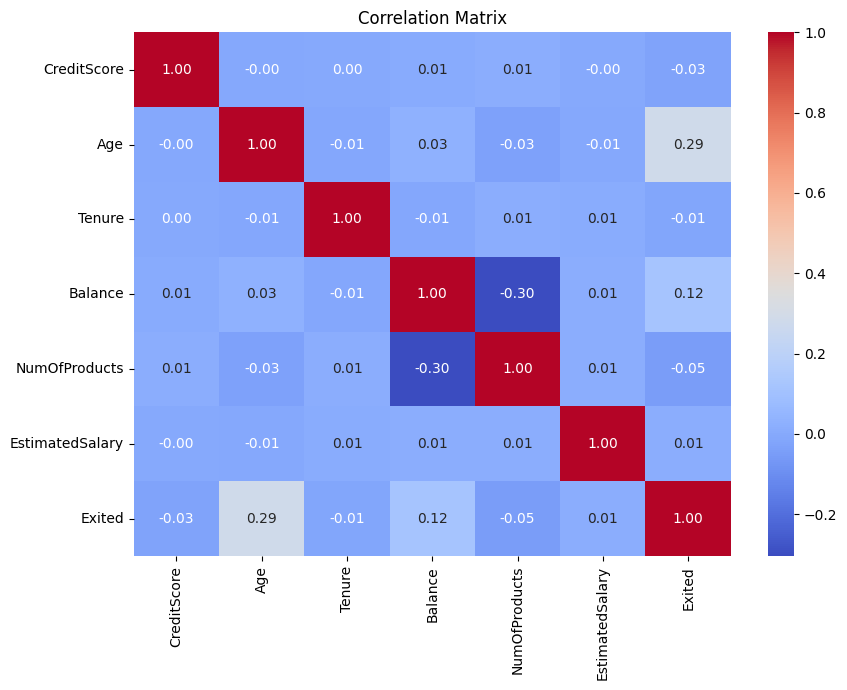

In [8]:
plt.figure(figsize=(9, 7))
corr = data_new[numerical_features + ['Exited']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

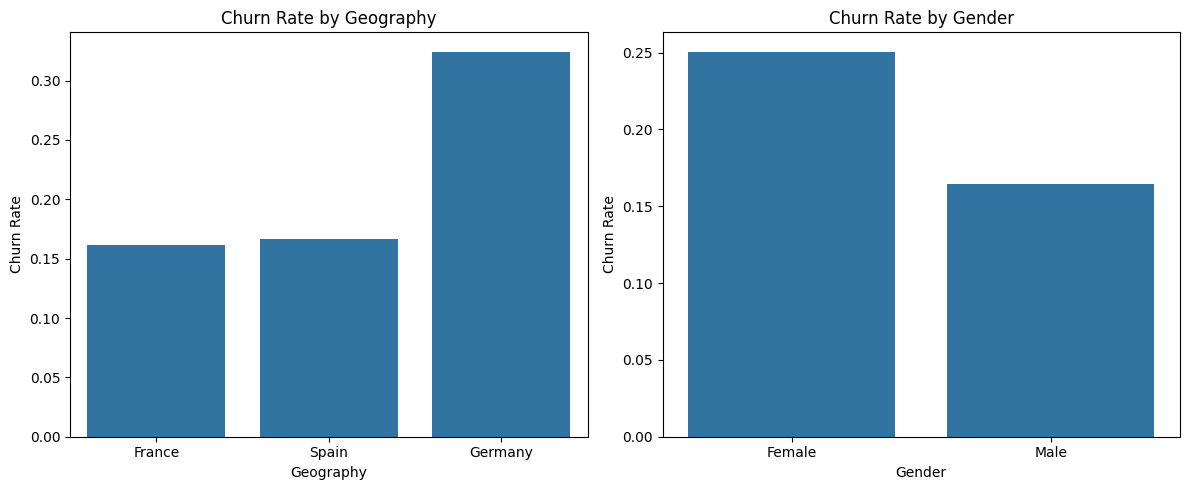

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x='Geography', y='Exited', data=data_new, ax=axes[0], errorbar=None)
axes[0].set_title('Churn Rate by Geography')
axes[0].set_ylabel('Churn Rate')

sns.barplot(x='Gender', y='Exited', data=data_new, ax=axes[1], errorbar=None)
axes[1].set_title('Churn Rate by Gender')
axes[1].set_ylabel('Churn Rate')

plt.tight_layout()
plt.show()

## 3. Preprocessing

`Gender` is binary, so label-encoding it is harmless. `Geography` (France / Germany / Spain) is **nominal**, not ordinal — the original notebook label-encoded it too, which implies a false 0 < 1 < 2 ordering. One-hot encoding it instead removes that assumption.

In [10]:
encoder_gen = LabelEncoder()
data_new['Gender'] = encoder_gen.fit_transform(data_new['Gender'])

data_new = pd.get_dummies(data_new, columns=['Geography'], drop_first=True)

data_new.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


## 4. Train/Test Split

**This is the fix for the critical bug.** The original notebook did:

```python
x = data_new.drop(['Exited'], axis=1)
y = data_new['Exited']
x_train, x_test, y_train, y_test = train_test_split(data_new, y, train_size=0.8)
```

`data_new.drop(...)` returns a new dataframe (`x`) — it does not modify `data_new` in place. The split was built from `data_new`, which still contained `Exited`, so the model was trained with the label as one of its own input features. Below, the split is built from `x` instead, with `random_state` set for reproducibility and `stratify=y` to keep the ~80/20 class balance consistent between train and test.

In [11]:
x = data_new.drop(['Exited'], axis=1)
y = data_new['Exited']

print("Confirming Exited is not a feature:", 'Exited' in x.columns)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.8, random_state=42, stratify=y
)

print("Train shape:", x_train.shape, " Test shape:", x_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), " Test churn rate:", round(y_test.mean(), 4))

Confirming Exited is not a feature: False
Train shape: (8000, 11)  Test shape: (2000, 11)
Train churn rate: 0.2037  Test churn rate: 0.2035


## 5. Baseline Classifier: Decision Tree (default hyperparameters)

The original notebook used `DecisionTreeRegressor` on a binary target and evaluated it with `r2_score` — neither is meaningful for classification. This is the corrected baseline: `DecisionTreeClassifier`, evaluated with confusion matrix, precision/recall/F1, and ROC-AUC.

In [12]:
baseline_model = DecisionTreeClassifier(random_state=42)
baseline_model.fit(x_train, y_train)

y_pred_baseline = baseline_model.predict(x_test)
y_proba_baseline = baseline_model.predict_proba(x_test)[:, 1]

print(confusion_matrix(y_test, y_pred_baseline))
print()
print(classification_report(y_test, y_pred_baseline, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_baseline), 4))

[[1360  233]
 [ 194  213]]

              precision    recall  f1-score   support

           0     0.8752    0.8537    0.8643      1593
           1     0.4776    0.5233    0.4994       407

    accuracy                         0.7865      2000
   macro avg     0.6764    0.6885    0.6819      2000
weighted avg     0.7943    0.7865    0.7901      2000

ROC-AUC: 0.6885


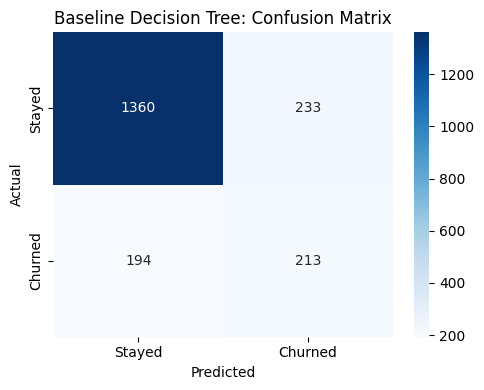

In [13]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_baseline),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned']
)
plt.title('Baseline Decision Tree: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

This is the honest version of what the original notebook's `[[1597, 0], [0, 403]]` was standing in for. 78.7% accuracy, but only 52.3% recall and 47.8% precision on the churn class — the baseline tree, unconstrained, is overfitting the training set and generalizing weakly. Section 6 checks whether a better-tuned model, or a different algorithm entirely, does meaningfully better.

## 6. Improved Modelling: Comparing Classifiers

Instead of guessing hyperparameters, `max_depth` is selected by 5-fold cross-validation on the training set only (the test set is never touched until final evaluation), then compared against a Random Forest and a Logistic Regression baseline.

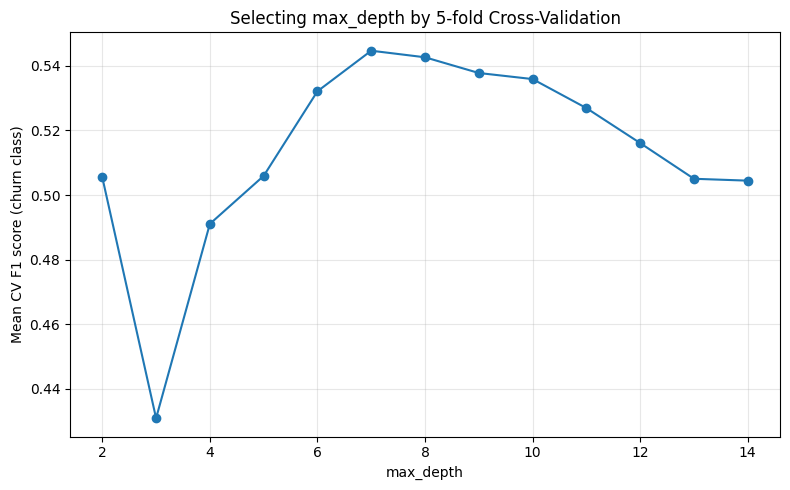

Best max_depth by CV F1: 7 (F1 = 0.5447)


In [14]:
depth_values = list(range(2, 15))
cv_f1_scores = []

for depth in depth_values:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(dt, x_train, y_train, cv=5, scoring='f1')
    cv_f1_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(depth_values, cv_f1_scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Mean CV F1 score (churn class)')
plt.title('Selecting max_depth by 5-fold Cross-Validation')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_depth = depth_values[int(np.argmax(cv_f1_scores))]
print(f"Best max_depth by CV F1: {best_depth} (F1 = {max(cv_f1_scores):.4f})")

In [15]:
tuned_tree_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tuned_tree_model.fit(x_train, y_train)

rf_model = RandomForestClassifier(n_estimators=300, random_state=42)
rf_model.fit(x_train, y_train)

# Logistic Regression benefits from scaled features; fit the scaler on the
# training set only and apply it to the test set to avoid leaking test
# statistics into the transform.
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(x_train_scaled, y_train)

print("Models fit.")

Models fit.


In [16]:
def evaluate(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

comparison_rows = [
    evaluate(
        "Baseline Decision Tree (default)", y_test,
        y_pred_baseline, y_proba_baseline
    ),
    evaluate(
        f"Decision Tree (max_depth={best_depth})", y_test,
        tuned_tree_model.predict(x_test), tuned_tree_model.predict_proba(x_test)[:, 1]
    ),
    evaluate(
        "Random Forest (300 trees)", y_test,
        rf_model.predict(x_test), rf_model.predict_proba(x_test)[:, 1]
    ),
    evaluate(
        "Logistic Regression", y_test,
        lr_model.predict(x_test_scaled), lr_model.predict_proba(x_test_scaled)[:, 1]
    ),
]

model_comparison = pd.DataFrame(comparison_rows).round(4)
model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline Decision Tree (default),0.7865,0.4776,0.5233,0.4994,0.6885
1,Decision Tree (max_depth=7),0.8535,0.6875,0.5135,0.5879,0.8297
2,Random Forest (300 trees),0.8635,0.7724,0.4668,0.5819,0.8542
3,Logistic Regression,0.8080,0.5891,0.1867,0.2836,0.7748


Random Forest has the highest accuracy, precision, and ROC-AUC. The depth-7 decision tree has the highest F1 score (0.588 vs. 0.582) and higher recall than the forest. The untuned baseline tree has the highest recall overall (52%) but much lower precision (48%). This is a real tradeoff, not a rounding error: Random Forest catches fewer actual churners (47% recall vs. 51%) but is right more often when it does flag one (77% precision vs. 69%). Logistic Regression is clearly the weakest of the four — 19% recall means it misses roughly 4 out of 5 churners, consistent with a plain linear decision boundary struggling against this feature set without any class-imbalance correction (see Limitations).

**Random Forest is selected as the final model below**, on ROC-AUC — the more robust, threshold-independent metric for a ranking/risk-scoring use case like churn. If the business priority is catching as many at-risk customers as possible even at the cost of more false alarms, the depth-7 tree is the better choice instead; that's a business call, not a modelling one.

In [17]:
final_model = rf_model
final_pred = final_model.predict(x_test)
final_proba = final_model.predict_proba(x_test)[:, 1]

## 7. Final Model: Random Forest — Detailed Evaluation

In [18]:
print(confusion_matrix(y_test, final_pred))
print()
print(classification_report(y_test, final_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, final_proba), 4))

[[1537   56]
 [ 217  190]]

              precision    recall  f1-score   support

           0     0.8763    0.9648    0.9184      1593
           1     0.7724    0.4668    0.5819       407

    accuracy                         0.8635      2000
   macro avg     0.8243    0.7158    0.7502      2000
weighted avg     0.8551    0.8635    0.8500      2000

ROC-AUC: 0.8542


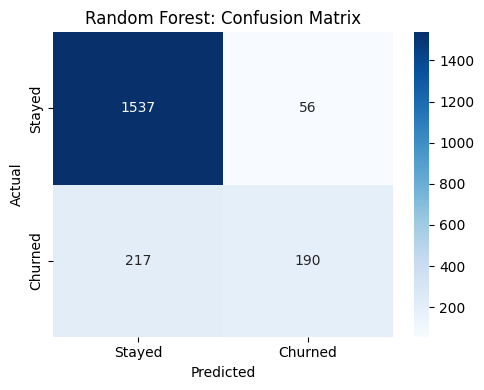

In [19]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, final_pred),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned']
)
plt.title('Random Forest: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

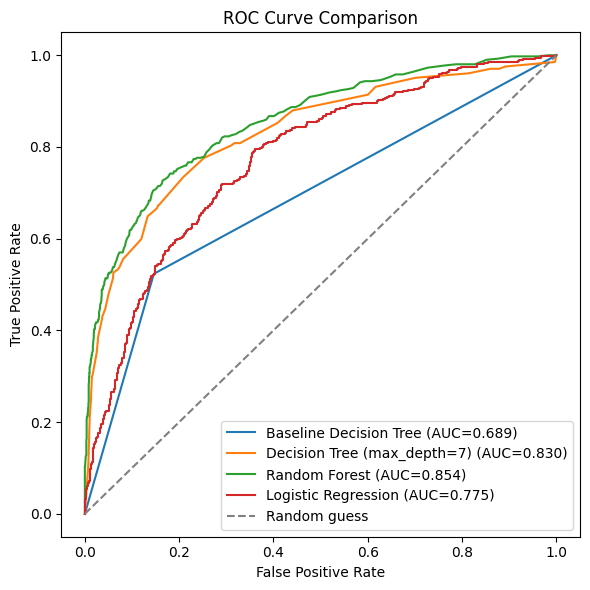

In [20]:
plt.figure(figsize=(6, 6))

for name, proba in [
    ("Baseline Decision Tree", y_proba_baseline),
    (f"Decision Tree (max_depth={best_depth})", tuned_tree_model.predict_proba(x_test)[:, 1]),
    ("Random Forest", final_proba),
    ("Logistic Regression", lr_model.predict_proba(x_test_scaled)[:, 1]),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Verifying There's No Leakage: Feature Importances

The original (broken) notebook's model assigned **100% of its feature importance to a column literally named `Exited`**, and 0% to every real feature — the unambiguous signature of the label leaking into the inputs. `Exited` is no longer even present in `x.columns`, so that specific failure is now structurally impossible. As a further check, the importances below should be spread across genuine customer attributes rather than dominated by any single column.

Age                  0.2384
EstimatedSalary      0.1472
Balance              0.1432
CreditScore          0.1427
NumOfProducts        0.1259
Tenure               0.0810
IsActiveMember       0.0417
Geography_Germany    0.0280
HasCrCard            0.0190
Gender               0.0187
Geography_Spain      0.0142
dtype: float64


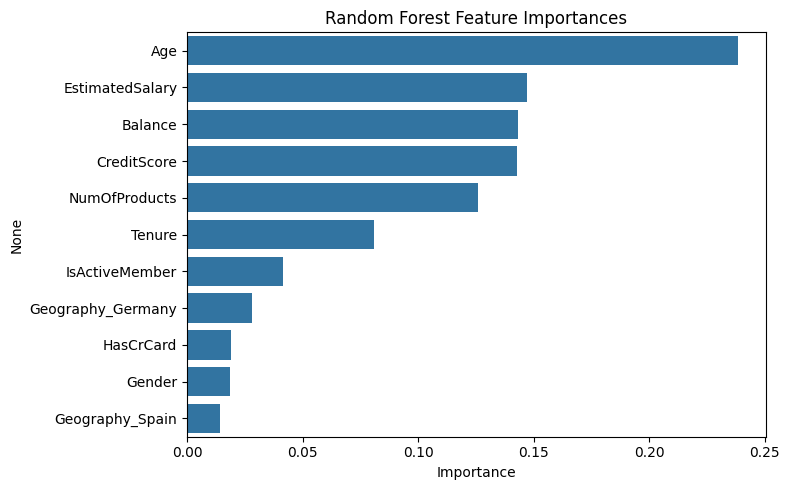

In [21]:
importances = (
    pd.Series(rf_model.feature_importances_, index=x_train.columns)
    .sort_values(ascending=False)
)
print(importances.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

`Age` is the single strongest predictor, followed by `EstimatedSalary`, `Balance`, `CreditScore`, and `NumOfProducts` — no column dominates the way `Exited` did in the original model, and every top feature is a genuine customer attribute rather than a copy of the target.

## Limitations

- **Class imbalance is not corrected.** ~20% of customers churn. None of the four models here use `class_weight='balanced'`, oversampling (e.g. SMOTE), or a tuned decision threshold. This is the most likely lever for improving recall on the churn class without a fundamentally different model.
- **Hyperparameter search is narrow.** Only `max_depth` was tuned for the decision tree, over a single train/CV split; Random Forest and Logistic Regression were run close to their defaults. A proper grid/random search (tree depth, min-samples-per-leaf, forest size, regularization strength) would likely move these numbers further.
- **No calibration check.** `predict_proba` outputs are used directly for ROC-AUC without checking whether they're well-calibrated probabilities — matters if this model is meant to rank customers by churn risk for a retention campaign rather than just classify them.
- **Random Forest vs. depth-limited tree is a genuine tradeoff, not a settled choice** (see Section 6) — the "right" final model depends on whether the business cares more about precision or recall, which this notebook doesn't have enough context to decide unilaterally.
- **Geography is one-hot encoded**, which is the correct fix over the original's label-encoding, but was not re-validated against any external source — confirm `France` / `Germany` / `Spain` are genuinely nominal with no natural ordering relevant to this business before reusing this choice elsewhere.